# Joint vs R2D2M2 vs stated scales on real designs, refitted by lme4

## 1. Motivation

The [simulated datasets](simulated.ipynb) compared three ways to set the prior scales of a Bayesian generalized linear mixed model (GLMM).<br>
Only the joint prior kept the marginal R² and the links' saturation flat as the design grew.<br>
But that comparison read every measure off the ground truth, on simulated covariates.<br>
So it could not say whether a prior's levels match those of real grouped tables.

This experiment draws y on the designs of real tables instead.<br>
lme4 refits each drawn y, as it fitted the real one.<br>
If a prior could have produced the real tables, each real fit falls at a random rank among its refits.

**Contents**
1. Motivation
2. Design
3. Measures
4. Reading
5. Records
6. Ranks
7. Outside, containment and distance
8. Singular fits and the slope over d
9. Finding

References

## 2. Design

Each real table lends its design to every prior, and lme4 (Bates et al., 2015) fits both sides alike.
- **Registry:** real grouped tables from public sources, each with the mixed model its documentation fits, collected and fitted by lme4 in MixedBench 1.0.12.
- **Fits:** each documented model with estimates and an intercept, on the rows it was fitted on (section 5 counts the rest).
- **Design:** the design matrix X and each grouping factor's random-effect columns Z_k, as lme4 builds them from the documented formula, with its offset.
- **Columns:** X's columns other than 0/1 z-scored, which the refit's intercept and slopes absorb.
- **Draws:** 10 per fit and prior, each a prior, its parameters and a y in the family the registry fitted (Gaussian, Bernoulli or Poisson).
- **Random effects:** correlated as the formula fits them, under a Lewandowski-Kurowicka-Joe (LKJ) prior for `(x | g)` and independent for `(x || g)`.
- **Refit:** the documented formula with the drawn y as its response, so each refit is the registry's fit with y swapped.
- **Priors:** the five of [simulated.ipynb's section 4](simulated.ipynb), `joint`, `r2d2m2-0.5`, `r2d2m2-1`, `survey` and `unit`.
- **Random streams:** shared by the five priors, so that they differ only in their scales.

`registry.py` builds the designs and draws and refits y, one cluster task per fit, and writes `registry.csv.gz`, which this notebook reads.

## 3. Measures

Each measure is read off a fit's estimates, the refit's or the registry's, by the variance partition of [simulated.ipynb's section 3](simulated.ipynb) (Nakagawa et al., 2017).
- **$R^2_m$, $R^2_c$ and the fixed share $R^2_m / R^2_c$:** one per fit.
- **Intraclass correlation (ICC):** one per grouping factor, every factor in one distribution, each paired with the same factor of the registry's fit.
- **sd(η):** the standard deviation of the fitted linear predictor over the rows, on the logit and log links only, since a Gaussian η is on y's raw scale.
- **Singular share:** the share of fits that lme4 flags as singular, with some variance estimated at 0 or some correlation at ±1.

A fit without slopes (d = 1) has $R^2_m$ = 0 and a fixed share of 0 on both sides.<br>
So it leaves those two measures, whose ties would otherwise pull its ranks toward uniform.

## 4. Reading

### Ranks

A registry fit's rank among the m refits under one prior runs from 0, below every refit, to m, above every refit.<br>
If real tables were draws from the prior, the rank would be uniform.<br>
Then 2 / (m + 1) of the fits would fall outside the refits' range, 2/11 ≈ 18 % at m = 10.<br>
Ties, as at the ICC of 0 of a singular fit, break at random in the histograms.<br>
The share outside takes the chance of a rank of 0 or m over that random draw, so that it does not depend on the draw.<br>
A fit with fewer refits, after an error or a timeout, spreads its rank r into 11 bins by (r + V) / (m + 1), with V uniform on [0, 1).<br>
At m = 10, the bin is r itself.

The ranks' histogram reads by its shape:
- **∩:** the prior is wider than real tables, as a prior meant to cover every table intends.
- **U:** the prior misses real tables on both sides.
- **Falling:** the refits lie above the registry, so the prior's levels are too high.
- **Rising:** the refits lie below the registry, so the prior's levels are too low.

### Containment and distance

Two more numbers compare the registry's fits with all refits under one prior, as two samples.
- **Containment:** the share of one sample inside the other's 1st to 99th percentile band, both ways.
- **Wide prior:** keeps the registry inside its refits' band, but not every refit inside the registry's.
- **Distance:** the Wasserstein-1 distance between the two samples' pooled ranks, from 0 to 1, without a test.

A classifier two-sample test is left out, since it rewards matching where a prior is meant to be wider.

### The joint prior's losses

The joint prior loses a measure of one family to another prior when two things hold.
- **Fewer outside:** the other prior leaves fewer registry fits outside its refits' range, with the paired difference's 95 % interval below 0.
- **No larger distance:** its Wasserstein-1 distance is at most the joint prior's.

The paired difference compares the same fits under both priors.<br>
Its interval takes the normal approximation, clustered by fit, since a fit's factors share its design.

### The slope over d

The slope of $R^2_m$ over the design matrix's rank d says how fast the explained variance climbs with d.<br>
Each fit's $R^2_m$ in the registry, or its mean over the refits under one prior, is regressed on log₂ d.<br>
The regression is ordinary least squares (OLS) over the fits with d ≥ 2, with a 95 % interval by the normal approximation.

## 5. Records

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mixedbench import registry

from tabdgp import fidelity

SEED = 2026  # the ties' and the bins' random draws
ESTIMATED = ['ok', 'singular', 'warning']  # the statuses of a fit with estimates
FAMILIES = ['gaussian', 'bernoulli', 'poisson']
ARMS = ['joint', 'r2d2m2-0.5', 'r2d2m2-1', 'survey', 'unit']

fits = pd.read_csv('registry-fits.csv')  # a row per registry model, its task or why it was dropped
tasks = fits[fits['task'].notna()].astype({'task': int, 'rank': int, 'factors': int})
records = pd.read_csv('registry.csv.gz')  # a row per fit, draw and prior
records = records.merge(tasks[['task', 'family', 'rank']], on='task')
print(f'{len(tasks)} of {len(fits)} registry models, {len(records)} refits')

515 of 613 registry models, 25750 refits


In [2]:
# the registry's models that have no task, by why they were dropped
dropped = fits[fits['task'].isna()]
print(pd.crosstab(dropped['reason'], dropped['family'])[FAMILIES].to_string())

family                 gaussian  bernoulli  poisson
reason                                             
no estimates                 72          9        4
no intercept                  5          0        1
rows unlike the fit's         3          2        2


A refit without estimates ended in an error or a timeout.<br>
Most errors come from a y that lme4 cannot fit: a constant y, or a ground truth that saturates the link.<br>
So the errors count against their prior, and its ranks are taken over the refits that remain.

In [3]:
# the share of refits without estimates, per family and prior
statuses = pd.crosstab(
    [records['family'], records['arm']], records['fit_status'], normalize='index'
)
print(statuses['error'].unstack('family')[FAMILIES].round(3).to_string())
print(f'timeouts: {int((records["fit_status"] == "timeout").sum())}')

family      gaussian  bernoulli  poisson
arm                                     
joint          0.000      0.068    0.079
r2d2m2-0.5     0.000      0.060    0.091
r2d2m2-1       0.000      0.053    0.087
survey         0.003      0.050    0.256
unit           0.000      0.059    0.097
timeouts: 22


In [4]:
MEASURES = {
    'r2_marginal': '$R^2_m$',
    'r2_conditional': '$R^2_c$',
    'fixed_share': '$R^2_m / R^2_c$',
    'icc': 'ICC',
    'sd_eta': 'sd(η)',
}
PER_FIT = ['r2_marginal', 'r2_conditional', 'fixed_share', 'sd_eta']  # one value per fit


def selectMeasures(table: pd.DataFrame) -> pd.DataFrame:
    # sd(η) only on the logit and log links, R²_m and the fixed share only on fits with slopes
    table = table.merge(tasks[['task', 'family', 'rank']], on='task')
    raw_scale = (table['family'] == 'gaussian') & (table['measure'] == 'sd_eta')
    no_slopes = (table['rank'] == 1) & table['measure'].isin(['r2_marginal', 'fixed_share'])
    return table[~raw_scale & ~no_slopes]


def readRegistry() -> pd.DataFrame:
    # fits.csv holds a row per grouping factor, the fit's own measures repeated on each
    reference = pd.read_csv(registry.path('fits.csv'), keep_default_na=False, na_values=[''])
    reference['id'] = (
        reference['source'] + '/' + reference['object'] + '/' + reference['model_index'].astype(str)
    )
    reference = reference.merge(tasks[['id', 'task']], on='id')

    # the fit's own measures, the fixed share at the records' 4 decimals
    per_fit = reference.drop_duplicates('task').copy()
    explained = per_fit['sigma2_fixed'] + per_fit['sigma2_random']
    per_fit['fixed_share'] = (per_fit['sigma2_fixed'] / explained).round(4)
    measures = per_fit.melt(id_vars='task', value_vars=PER_FIT, var_name='measure')
    measures['k'] = 0

    # each factor's ICC, k in lme4's order, which is the order of a fit's rows and its refits' columns
    factors = reference[['task', 'icc']].rename(columns={'icc': 'value'})
    factors['k'] = factors.groupby('task').cumcount() + 1
    factors['measure'] = 'icc'
    return selectMeasures(pd.concat([measures, factors]).dropna(subset=['value']))


def readRefits() -> pd.DataFrame:
    # each refit's measures beside its ground truth's
    fitted = records[records['fit_status'].isin(ESTIMATED)]
    parts = []
    for measure in PER_FIT:
        part = fitted[['task', 'draw', 'arm']].assign(
            measure=measure, k=0, value=fitted[f'fit_{measure}'], truth=fitted[f'truth_{measure}']
        )
        parts.append(part)
    for k in range(1, tasks['factors'].max() + 1):
        part = fitted[['task', 'draw', 'arm']].assign(
            measure='icc', k=k, value=fitted[f'fit_icc_{k}'], truth=fitted[f'truth_icc_{k}']
        )
        parts.append(part)
    return selectMeasures(pd.concat(parts).dropna(subset=['value']))


real = readRegistry()  # a row per fit, measure and factor (k = 0 for a fit's own measure)
refits = readRefits()  # a row per refit, measure and factor

### Check: ground truth against refit

A refit is only informative if it recovers its ground truth's measures.<br>
A Bernoulli y recovers them least, since one binary draw per row carries little information.

In [5]:
# Spearman's correlation between each ground truth's measure and its refit's
correlations = {}
for (family, measure, arm), table in refits.groupby(['family', 'measure', 'arm']):
    correlations[(family, MEASURES[measure], arm)] = table['truth'].corr(
        table['value'], method='spearman'
    )
print(pd.Series(correlations).unstack().round(2).to_string())

                           joint  r2d2m2-0.5  r2d2m2-1  survey  unit
bernoulli $R^2_c$           0.78        0.80      0.75    0.82  0.78
          $R^2_m / R^2_c$   0.68        0.81      0.80    0.86  0.82
          $R^2_m$           0.76        0.86      0.81    0.86  0.83
          ICC               0.73        0.79      0.78    0.85  0.81
          sd(η)             0.78        0.78      0.73    0.79  0.78
gaussian  $R^2_c$           0.98        0.98      0.98    0.99  0.99
          $R^2_m / R^2_c$   0.85        0.82      0.84    0.89  0.92
          $R^2_m$           0.94        0.97      0.97    0.96  0.97
          ICC               0.89        0.85      0.86    0.92  0.93
poisson   $R^2_c$           0.89        0.91      0.92    0.90  0.86
          $R^2_m / R^2_c$   0.81        0.77      0.77    0.88  0.85
          $R^2_m$           0.82        0.87      0.86    0.90  0.86
          ICC               0.86        0.82      0.85    0.92  0.89
          sd(η)             0.87  

## 6. Ranks

Each row of a figure is one measure.<br>
Its first panel shows the measure's distribution in the registry and under each prior, as empirical cumulative distribution functions (CDFs).<br>
The other panels show the registry's ranks under each prior, with the uniform share of 1/11 dashed.

In [6]:
def rankRegistry(rng: np.random.Generator) -> pd.DataFrame:
    # each registry estimate against the refits of its fit and factor under each prior
    paired = refits.merge(
        real[['task', 'measure', 'k', 'value']],
        on=['task', 'measure', 'k'],
        suffixes=('', '_registry'),
    )
    paired['below'] = paired['value'] < paired['value_registry']
    paired['tied'] = paired['value'] == paired['value_registry']
    ranks = paired.groupby(['family', 'measure', 'task', 'k', 'arm'], as_index=False).agg(
        below=('below', 'sum'), tied=('tied', 'sum'), refits=('value', 'size')
    )

    # the histogram's bin: ties broken at random, the rank spread into 11 bins by (r + V) / (m + 1)
    rank = ranks['below'] + rng.integers(0, ranks['tied'] + 1)
    spread = (rank + rng.random(len(ranks))) / (ranks['refits'] + 1)
    ranks['bin'] = np.floor(11 * spread).astype(int)

    # the chance that the random tie-break puts the rank at 0 or at m
    at_bottom = (ranks['below'] == 0) / (ranks['tied'] + 1)
    at_top = (ranks['below'] + ranks['tied'] == ranks['refits']) / (ranks['tied'] + 1)
    ranks['outside'] = at_bottom + at_top
    ranks['expected'] = 2 / (ranks['refits'] + 1)  # the share outside if the ranks are uniform
    return ranks


ranks = rankRegistry(np.random.default_rng(SEED))

In [7]:
# three hues (joint, R2D2M2, stated), a dashed line for each one's second variant
ARM_STYLES = {
    'joint': {'color': '#2a78d6', 'linestyle': '-'},
    'r2d2m2-0.5': {'color': '#eb6834', 'linestyle': '-'},
    'r2d2m2-1': {'color': '#eb6834', 'linestyle': '--'},
    'survey': {'color': '#1baf7a', 'linestyle': '-'},
    'unit': {'color': '#1baf7a', 'linestyle': '--'},
}


def plotRanks(family: str) -> None:
    # one family's distributions and ranks per measure, saved as registry-<family>.pdf
    measures = []
    for measure in MEASURES:
        if (real[real['family'] == family]['measure'] == measure).any():
            measures.append(measure)
    figure, axes = plt.subplots(
        len(measures),
        1 + len(ARMS),
        figsize=(13, 2.1 * len(measures)),
        squeeze=False,
        layout='constrained',
    )
    for row, measure in enumerate(measures):
        ax = axes[row, 0]
        in_registry = real[(real['family'] == family) & (real['measure'] == measure)]
        ax.ecdf(in_registry['value'], color='black', linewidth=2.5, label='registry')
        under_arms = refits[(refits['family'] == family) & (refits['measure'] == measure)]
        for arm, style in ARM_STYLES.items():
            ax.ecdf(under_arms[under_arms['arm'] == arm]['value'], **style, label=arm)
        if measure == 'sd_eta':
            # the stated priors' extremes would squeeze the registry's range
            ax.set_xscale('log')
            ax.set_xlim(in_registry['value'].min() / 10, in_registry['value'].max() * 10)
        ax.set_ylabel(MEASURES[measure])
        ax.grid(color='#e4e3df', linewidth=0.6)
        ax.spines[['top', 'right']].set_visible(False)

        # each prior's ranks, on one y scale per row
        ranked = ranks[(ranks['family'] == family) & (ranks['measure'] == measure)]
        shares = {}
        for arm in ARMS:
            bins = ranked[ranked['arm'] == arm]['bin']
            shares[arm] = np.bincount(bins, minlength=11) / len(bins)
        top = 1.05 * max(share.max() for share in shares.values())
        for column, arm in enumerate(ARMS, start=1):
            ax = axes[row, column]
            ax.bar(range(11), shares[arm], width=0.85, color=ARM_STYLES[arm]['color'])
            ax.axhline(1 / 11, color='black', linestyle='--', linewidth=1)
            ax.set_ylim(0, top)
            ax.set_xticks([0, 5, 10])
            ax.spines[['top', 'right']].set_visible(False)
            if row == 0:
                ax.set_title(arm)
            if row == len(measures) - 1:
                ax.set_xlabel("registry's rank")
    axes[0, 0].set_title('distribution')
    axes[-1, 0].set_xlabel('value')
    handles, labels = axes[0, 0].get_legend_handles_labels()
    figure.legend(handles, labels, loc='outside lower center', ncol=len(labels), frameon=False)
    figure.suptitle(f'{family} y')
    figure.savefig(f'registry-{family}.pdf', metadata={'CreationDate': None})

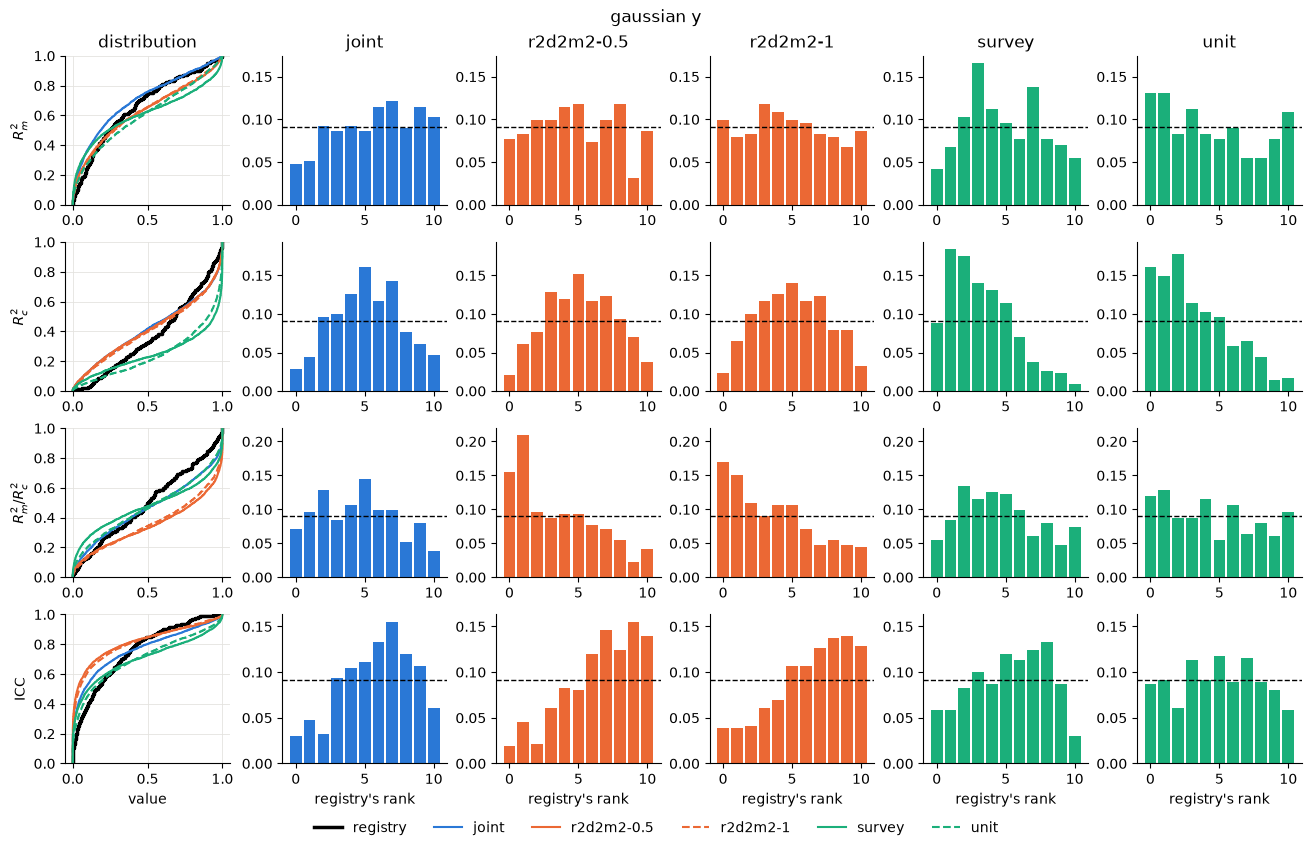

In [8]:
plotRanks('gaussian')

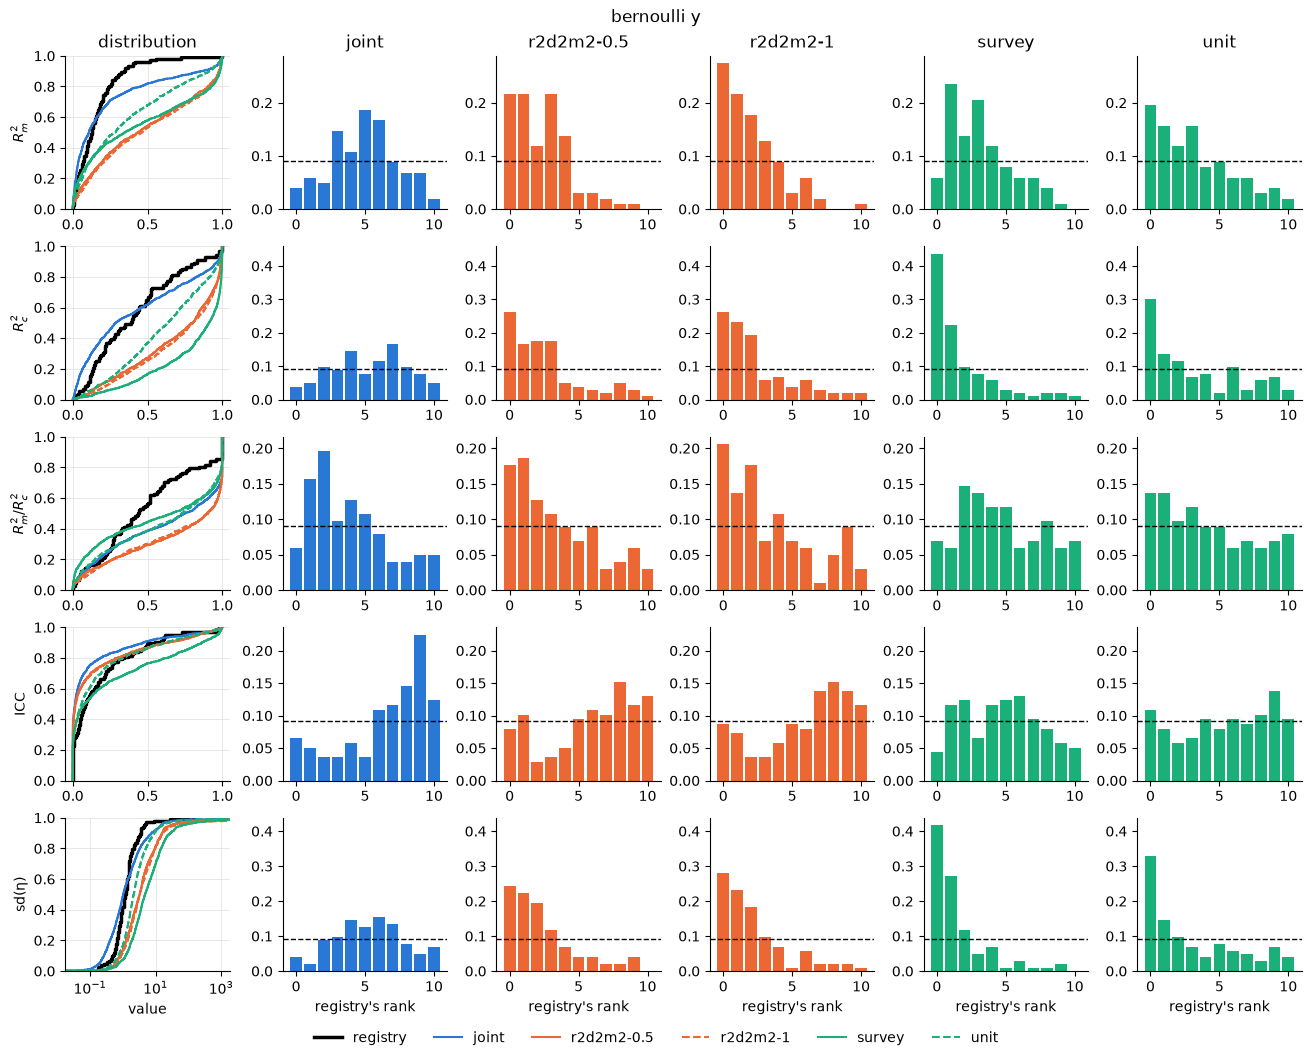

In [9]:
plotRanks('bernoulli')

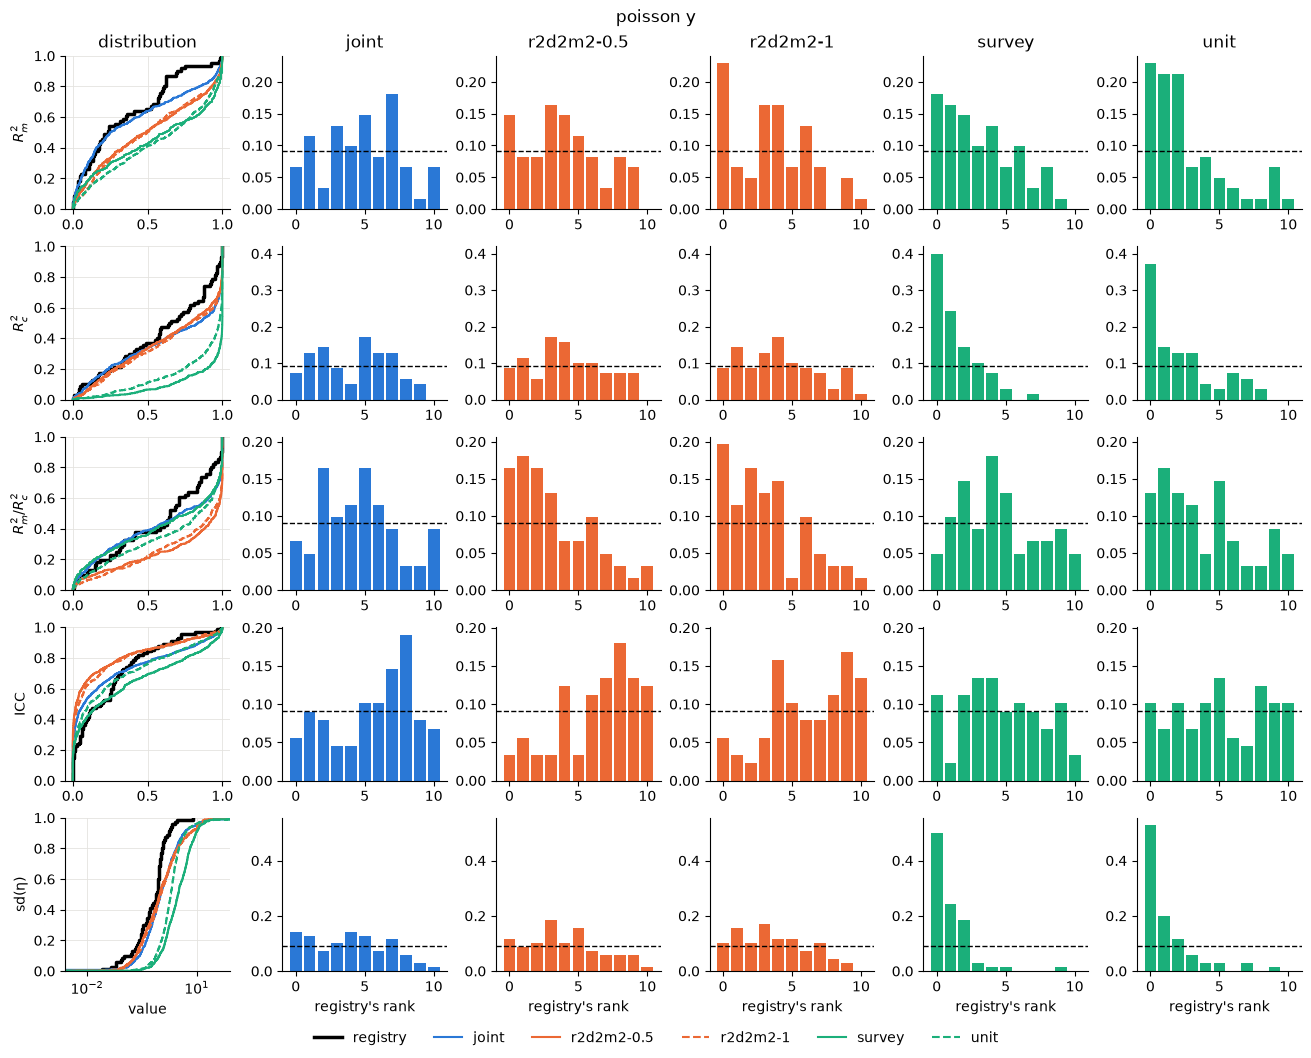

In [10]:
plotRanks('poisson')

## 7. Outside, containment and distance

Per family, measure and prior:
- **outside:** the share of registry fits outside the refits' range.
- **expected:** that share if the ranks are uniform.
- **vs joint:** the paired difference to the joint prior's share outside, with its 95 % interval.
- **distance:** the Wasserstein-1 distance between the registry and the refits.
- **refits in:** the share of refits inside the registry's band.
- **registry in:** the share of registry fits inside the refits' band.

In [11]:
def intervalPaired(difference: pd.Series) -> tuple[float, float]:
    # the mean's 95 % interval by the normal approximation, clustered by fit
    residuals = (difference - difference.mean()).groupby(level='task').sum()  # (fits,)
    clusters = len(residuals)
    variance = (residuals**2).sum() * clusters / (clusters - 1) / len(difference) ** 2
    half = 1.96 * math.sqrt(variance)
    return difference.mean() - half, difference.mean() + half


def compareArms(rng: np.random.Generator) -> pd.DataFrame:
    # a row per family, measure and prior
    outside = ranks.pivot_table(
        index=['family', 'measure', 'task', 'k'], columns='arm', values='outside'
    )
    rows = []
    for family in FAMILIES:
        for measure, label in MEASURES.items():
            in_registry = real[(real['family'] == family) & (real['measure'] == measure)]
            if in_registry.empty:
                continue
            registry_values = in_registry['value'].to_numpy()[:, None]  # (s, 1)
            ranked = ranks[(ranks['family'] == family) & (ranks['measure'] == measure)]
            units = outside.loc[(family, measure)]
            for arm in ARMS:
                under_arm = refits[
                    (refits['family'] == family)
                    & (refits['measure'] == measure)
                    & (refits['arm'] == arm)
                ]
                refit_values = under_arm['value'].to_numpy()[:, None]  # (s, 1)
                [distance] = fidelity.distances(registry_values, refit_values, rng, permutations=0)
                low, high = math.nan, math.nan
                if arm != 'joint':
                    low, high = intervalPaired(units[arm] - units['joint'])
                rows.append(
                    {
                        'family': family,
                        'measure': label,
                        'arm': arm,
                        'outside': units[arm].mean(),
                        'expected': ranked[ranked['arm'] == arm]['expected'].mean(),
                        'vs joint': units[arm].mean() - units['joint'].mean(),
                        'low': low,
                        'high': high,
                        'distance': distance.statistic,
                        'refits in': fidelity.containment(refit_values, registry_values).per_axis[
                            0
                        ],
                        'registry in': fidelity.containment(registry_values, refit_values).per_axis[
                            0
                        ],
                    }
                )
    return pd.DataFrame(rows).set_index(['family', 'measure', 'arm'])


comparison = compareArms(np.random.default_rng(SEED))
for family in FAMILIES:
    print(comparison.loc[family].round(3).to_string(), end='\n\n')

                            outside  expected  vs joint    low   high  distance  refits in  registry in
measure         arm                                                                                    
$R^2_m$         joint         0.149     0.182     0.000    NaN    NaN     0.057      0.984        0.974
                r2d2m2-0.5    0.161     0.182     0.013 -0.025  0.050     0.049      0.966        0.994
                r2d2m2-1      0.184     0.182     0.035 -0.005  0.075     0.043      0.972        0.990
                survey        0.094     0.183    -0.054 -0.095 -0.014     0.084      0.924        0.994
                unit          0.238     0.182     0.089  0.043  0.136     0.059      0.973        0.990
$R^2_c$         joint         0.074     0.182     0.000    NaN    NaN     0.073      0.909        0.994
                r2d2m2-0.5    0.057     0.182    -0.017 -0.043  0.009     0.070      0.904        0.994
                r2d2m2-1      0.054     0.182    -0.020 -0.042  

In [12]:
# the measures the joint prior loses: another prior leaves fewer fits outside, at no larger distance
joint_distance = comparison.xs('joint', level='arm')['distance']
others = comparison.drop(index='joint', level='arm')
no_larger = others['distance'] <= joint_distance.reindex(others.index.droplevel('arm')).to_numpy()
losses = others[(others['high'] < 0) & no_larger]
if losses.empty:
    print('none')
else:
    print(losses[['outside', 'vs joint', 'high', 'distance']].round(3).to_string())

none


## 8. Singular fits and the slope over d

In [13]:
# the share of singular fits among the fits with estimates, in the registry and under each prior
fitted = records[records['fit_status'].isin(ESTIMATED)]
singular = (fitted['fit_status'] == 'singular').groupby([fitted['family'], fitted['arm']]).mean()
singular = singular.unstack()
singular.insert(0, 'registry', (tasks['status'] == 'singular').groupby(tasks['family']).mean())
print(singular.loc[FAMILIES].round(3).to_string())

arm        registry  joint  r2d2m2-0.5  r2d2m2-1  survey   unit
family                                                         
gaussian      0.082  0.236       0.279     0.257   0.160  0.145
bernoulli     0.233  0.325       0.252     0.240   0.162  0.208
poisson       0.114  0.217       0.318     0.252   0.090  0.133


In [14]:
def fitSlope(d: pd.Series, r2: pd.Series) -> dict[str, float]:
    # OLS of R²_m on log₂ d, its slope's 95 % interval by the normal approximation
    centered = np.log2(d) - np.log2(d).mean()
    slope = (centered * r2).sum() / (centered**2).sum()
    residuals = r2 - r2.mean() - slope * centered
    se = math.sqrt((residuals**2).sum() / (len(r2) - 2) / (centered**2).sum())
    return {'slope': slope, 'low': slope - 1.96 * se, 'high': slope + 1.96 * se, 'fits': len(r2)}


slopes = {}
for family in FAMILIES:
    in_registry = real[(real['family'] == family) & (real['measure'] == 'r2_marginal')]
    slopes[(family, 'registry')] = fitSlope(in_registry['rank'], in_registry['value'])
    under_arms = refits[(refits['family'] == family) & (refits['measure'] == 'r2_marginal')]
    for arm in ARMS:
        per_fit = under_arms[under_arms['arm'] == arm].groupby('task')[['rank', 'value']].mean()
        slopes[(family, arm)] = fitSlope(per_fit['rank'], per_fit['value'])
print(pd.DataFrame(slopes).T.round(3).to_string())

                      slope    low   high   fits
gaussian  registry    0.014 -0.016  0.043  313.0
          joint       0.031  0.020  0.041  313.0
          r2d2m2-0.5  0.096  0.083  0.109  313.0
          r2d2m2-1    0.094  0.081  0.106  313.0
          survey      0.079  0.062  0.095  313.0
          unit        0.100  0.082  0.117  313.0
bernoulli registry    0.067  0.033  0.102  102.0
          joint       0.038  0.007  0.070  102.0
          r2d2m2-0.5  0.119  0.084  0.153  102.0
          r2d2m2-1    0.126  0.091  0.161  102.0
          survey      0.097  0.062  0.131  102.0
          unit        0.135  0.099  0.171  102.0
poisson   registry    0.132  0.021  0.243   61.0
          joint       0.054  0.013  0.096   61.0
          r2d2m2-0.5  0.142  0.092  0.191   61.0
          r2d2m2-1    0.147  0.104  0.191   61.0
          survey      0.199  0.142  0.257   61.0
          unit        0.215  0.161  0.268   61.0


## 9. Finding

### Only the joint prior is wider than real tables on every link

- **Joint:** fewer fits outside its refits' range than uniform ranks on every measure.
- **Joint's band:** holds nearly every registry fit on every measure.
- **R2D2M2 and stated priors:** refits above the registry on the logit link's $R^2_m$, $R^2_c$ and sd(η).
- **Stated priors:** refits above the registry on the log link's $R^2_c$ and sd(η), where a quarter of the survey prior's refits fail.
- **Losses:** none, as only the survey prior leaves fewer fits outside on one measure, the Gaussian $R^2_m$, at a larger distance.

### The joint prior leans toward the fixed effects on the links

- **ICC:** rising ranks on the logit and log links, so its grouping factors explain less than real ones.
- **Fixed share:** falling ranks on the logit link, the same lean seen from the other side.
- **Singular fits:** more often than in the registry on every link.
- **η on the log link:** falling sd(η) ranks, so η is a little wider than in real tables.
- **Stated priors:** flat on the ICC, but far too high on $R^2_c$ and sd(η).

### The slope over d

- **Registry:** $R^2_m$ barely climbs with d on a Gaussian y, but climbs on the logit and log links.
- **Joint:** the flattest slope on every link, inside the registry's interval on all three.
- **The other priors:** climb faster than the registry's interval allows on a Gaussian y.

### Verdict

The joint prior stays, since no other prior takes a measure from it.<br>
It covers the levels of real grouped tables on every link, which [simulated.ipynb](simulated.ipynb) left open.<br>
Its lean toward the fixed effects on the logit and log links stays inside its width, so no default moves.<br>
These ranks do not say which default causes the lean.

## References

Aguilar, J. E., & Bürkner, P.-C. (2023). Intuitive joint priors for Bayesian linear multilevel models: The R2D2M2 prior. *Electronic Journal of Statistics*, *17*(1), 1711-1767. https://doi.org/10.1214/23-EJS2136

Bates, D., Mächler, M., Bolker, B., & Walker, S. (2015). Fitting linear mixed-effects models using lme4. *Journal of Statistical Software*, *67*(1), 1-48. https://doi.org/10.18637/jss.v067.i01

Nakagawa, S., Johnson, P. C. D., & Schielzeth, H. (2017). The coefficient of determination R² and intra-class correlation coefficient from generalized linear mixed-effects models revisited and expanded. *Journal of the Royal Society Interface*, *14*(134), 20170213. https://doi.org/10.1098/rsif.2017.0213